# Measure image shift inside a circular ROI

Estimate horizontal and vertical displacement **from the first image to the second**.

1. Put this notebook and your two images in the same folder, or set full paths below.
2. Run all cells to measure phase correlation.
3. Inspect the masked images and the visual check before using a measurement.

The phase method uses the centered circular ROI requested below. The original images are retained for measurement and alignment; display copies are black outside the circle. This notebook is self-contained.

In [1]:
# Run this line once if the packages are missing (remove the leading #).
# %pip install numpy opencv-python-headless matplotlib

In [1]:
%matplotlib inline
from pathlib import Path
import math
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

## Choose the images

Phase correlation estimates a translation from both images inside the same centered circle. Both images must have the same dimensions.

The circle has radius `min(height, width) // 2 - 100`. For the supplied 2560 × 1920 images, its center is `(1280, 960)` and radius is **860 pixels**.

A sharp, identical mask boundary can create a misleading zero-shift peak. The phase method therefore subtracts each image's weighted mean and applies a cosine taper **inside** the circle. Nothing outside the circle contributes. `EDGE_TAPER` controls the taper width in pixels.

In [17]:
IMAGE1 = Path("images/offset/5.bmp")   # reference / first image
IMAGE2 = Path("images/offset/6.bmp")   # second image

EDGE_TAPER = 80                      # phase window tapers within the circular boundary

if EDGE_TAPER <= 0:
    raise ValueError("EDGE_TAPER must be positive.")

## Measurement functions

Phase correlation uses a smooth circular window instead of the previous rectangular Hann window. Both frames use the exact same mask and window, without resizing, so shifts remain in original-image pixels.

The same mild Gaussian blur is applied to both frames.

In [18]:
def read_gray(path):
    data = np.fromfile(str(path), dtype=np.uint8)
    image = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Cannot read image: {path}")
    return image


def make_phase_window(mask, edge_taper=80):
    """Return a radial cosine taper with support strictly inside the binary ROI."""
    if mask.ndim != 2 or not np.any(mask):
        raise ValueError("Mask must be a nonempty 2D ROI.")
    if edge_taper <= 0:
        raise ValueError("edge_taper must be positive.")
    binary = ((mask > 0).astype(np.uint8) * 255)
    distance_inside = cv2.distanceTransform(binary, cv2.DIST_L2, 5)
    # Keep the 5×5 Gaussian neighborhood fully inside the ROI.
    t = np.clip((distance_inside - 3.0) / edge_taper, 0.0, 1.0)
    return (0.5 - 0.5 * np.cos(np.pi * t)).astype(np.float32)


def phase_shift_in_circle(image1, image2, mask, edge_taper=80):
    """Estimate image1 -> image2 translation using a smooth circular window.

    This is windowed phase correlation, not a general algorithm for arbitrary
    missing pixels. Enough translated texture must remain visible in both ROIs.
    The response is a peak diagnostic, not a probability or an accuracy bound.
    """
    if image1.ndim != 2 or image2.ndim != 2:
        raise ValueError("Inputs must be grayscale images.")
    if image1.shape != image2.shape or mask.shape != image1.shape:
        raise ValueError("Both images and the mask must have equal dimensions.")
    if image1.dtype != np.uint8 or image2.dtype != np.uint8:
        raise ValueError("Inputs must be uint8 grayscale images.")
    weight = make_phase_window(mask, edge_taper)
    weight_sum = float(weight.sum())
    if weight_sum < 10:
        raise ValueError("The ROI is too small.")
    valid = weight > 0
    prepared = []
    for image in (image1, image2):
        # Preserve the original 8-bit denoising step, then convert for the FFT.
        # Nonzero window weights are at least 3 pixels inside the mask, so this
        # 5×5 blur cannot introduce outside-ROI intensities into the estimate.
        smooth = cv2.GaussianBlur(image, (5, 5), 0).astype(np.float32)
        mean = float(np.sum(smooth * weight) / weight_sum)
        if float(np.std(smooth[valid])) < 1e-3:
            raise ValueError("Too little texture inside the circle.")
        # Subtract the mean BEFORE multiplying by the mask/window.
        prepared.append(np.ascontiguousarray((smooth - mean) * weight))
    (dx, dy), response = cv2.phaseCorrelate(prepared[0], prepared[1])
    result = (float(dx), float(dy), float(response))
    if not all(math.isfinite(value) for value in result):
        raise ValueError("No finite phase estimate was found.")
    return result


Images: 5.bmp -> 6.bmp
Dimensions: 2560 × 1920 pixels
Circular ROI: center=(1280, 960), radius=860 pixels


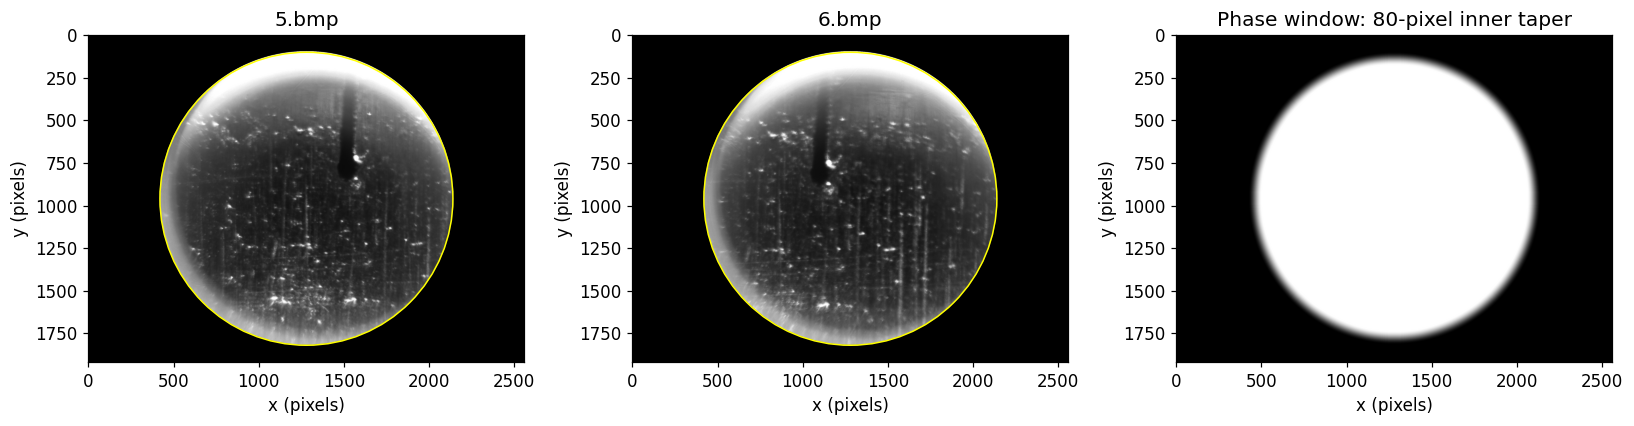

In [19]:
image1 = read_gray(IMAGE1)
image2 = read_gray(IMAGE2)
if image1.shape != image2.shape:
    raise ValueError("Use equal-sized images for this centered circular ROI.")

# Your exact circular ROI definition, applied identically to both frames.
img_cv = image1
radius = min(img_cv.shape[0], img_cv.shape[1]) // 2 - 100
center = (img_cv.shape[1] // 2, img_cv.shape[0] // 2)
if radius <= 0:
    raise ValueError("Image dimensions are too small for the 100-pixel margin.")
mask = np.zeros(img_cv.shape[:2], dtype=np.uint8)
cv2.circle(mask, center, radius, 255, -1)

# These black-background images are for display.
# Phase estimation below subtracts the mean and tapers before the FFT.
masked1 = cv2.bitwise_and(image1, image1, mask=mask)
masked2 = cv2.bitwise_and(image2, image2, mask=mask)
phase_window = make_phase_window(mask, EDGE_TAPER)

print(f"Images: {IMAGE1.name} -> {IMAGE2.name}")
print(f"Dimensions: {image1.shape[1]} × {image1.shape[0]} pixels")
print(f"Circular ROI: center={center}, radius={radius} pixels")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, image, title in zip(axes[:2], (masked1, masked2), (IMAGE1.name, IMAGE2.name)):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.add_patch(Circle(center, radius, fill=False, edgecolor="yellow", linewidth=1))
    ax.set_title(title)
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")
axes[2].imshow(phase_window, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"Phase window: {EDGE_TAPER}-pixel inner taper")
axes[2].set_xlabel("x (pixels)")
axes[2].set_ylabel("y (pixels)")
fig.tight_layout()
plt.show()

In [20]:
dx, dy, score = phase_shift_in_circle(image1, image2, mask, EDGE_TAPER)

distance = math.hypot(dx, dy)
print(f"Direction: {IMAGE1.name} -> {IMAGE2.name}")
print("Method: phase correlation inside circular ROI")
print(f"Horizontal shift dx = {dx:+.2f} pixels ({'right' if dx > 0 else 'left' if dx < 0 else 'none'})")
print(f"Vertical shift   dy = {dy:+.2f} pixels ({'down' if dy > 0 else 'up' if dy < 0 else 'none'})")
print(f"Total distance      = {distance:.2f} pixels")
print(f"Match score         = {score:.4f} (not a probability)")
print(f"To align image 2 to image 1, translate by ({-dx:+.2f}, {-dy:+.2f}) pixels.")

if score < 0.1:
    print("WARNING: Weak phase response. Do not trust this shift without a visual check.")
    print("The circular ROI does not solve appearance changes or inconsistent motion.")


Direction: 5.bmp -> 6.bmp
Method: phase correlation inside circular ROI
Horizontal shift dx = -416.87 pixels (left)
Vertical shift   dy = +29.95 pixels (down)
Total distance      = 417.94 pixels
Match score         = 0.4372 (not a probability)
To align image 2 to image 1, translate by (+416.87, -29.95) pixels.


## Visual check

For phase correlation, image 1 is **red** and image 2 is **cyan**. The second overlay applies the inverse measured translation. It shows only the intersection of the original circle with the translated circle, so excluded pixels cannot appear as alignment evidence. Stationary rim pixels can remain different even when the surface texture aligns.


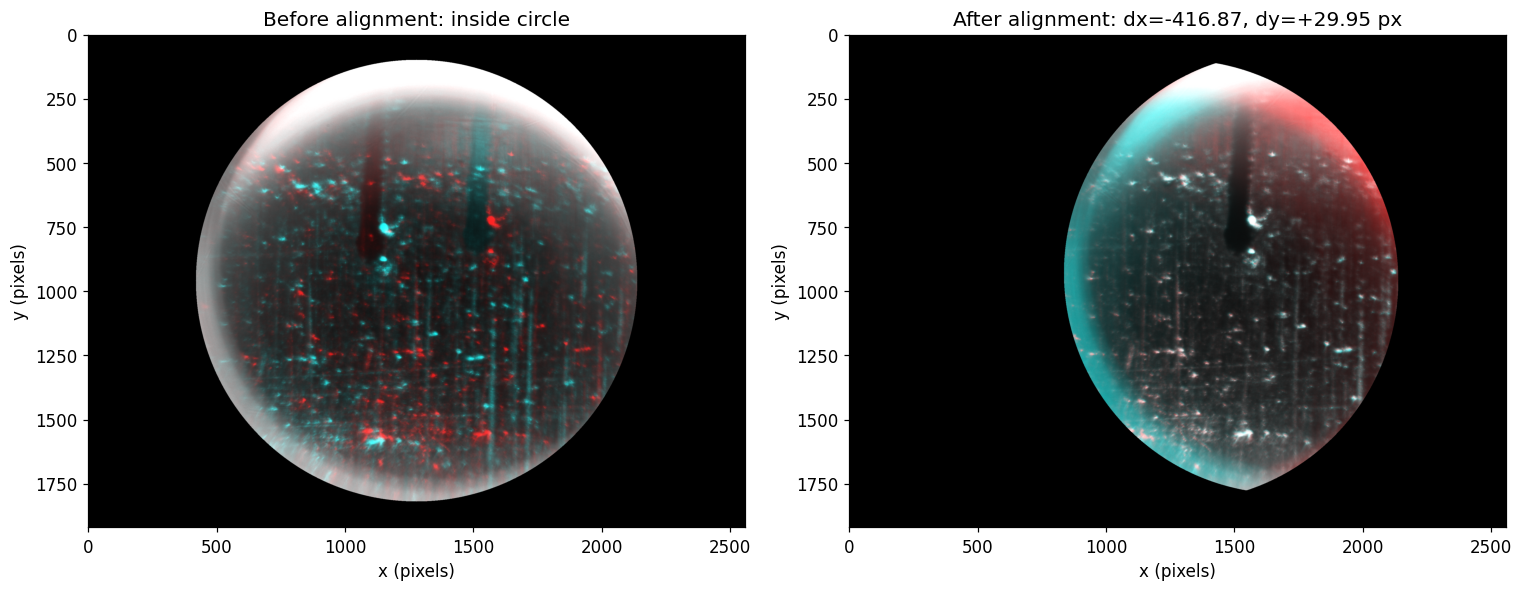

In [21]:
height, width = image1.shape
inverse_shift = np.float32([[1, 0, -dx], [0, 1, -dy]])
aligned2 = cv2.warpAffine(image2, inverse_shift, (width, height))
shifted_mask = cv2.warpAffine(mask, inverse_shift, (width, height), flags=cv2.INTER_NEAREST)
overlap = (mask > 0) & (shifted_mask > 0)

def red_cyan_overlay(first, second, valid_mask):
    overlay = np.dstack([first, second, second]).astype(np.float32) / 255.0
    overlay[~valid_mask] = 0
    return overlay

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].imshow(red_cyan_overlay(image1, image2, mask > 0))
axes[0].set_title("Before alignment: inside circle")
axes[1].imshow(red_cyan_overlay(image1, aligned2, overlap))
axes[1].set_title(f"After alignment: dx={dx:+.2f}, dy={dy:+.2f} px")
for ax in axes:
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")
fig.tight_layout()
plt.show()

## Interpreting the result

- Positive `dx` = right; negative `dx` = left. Positive `dy` = down; negative `dy` = up.
- Measurements use original pixels. A physical distance needs a pixels-per-millimetre calibration.
- Both phase inputs have the same circle center and dimensions. No coordinate offset correction is required.
- Enough corresponding texture must remain visible inside the two circles after motion. Large displacement, repeated patterns, rotation, or deformation can make one translation unreliable.
- The smooth edge is important: multiplying both images directly by the same sharp binary mask can create a stationary boundary and a false zero-shift peak. The binary circle is kept exactly for the ROI, with a smooth window inside it for phase correlation.
- The phase response is a diagnostic, not a probability. A nonzero response alone does not validate a result.
- The `2.bmp` / `3.bmp` pair still has a weak circular phase response. Inspect corresponding texture and the visual check before using the phase estimate.
- Phase correlation reports fractional pixels. Decimals do not guarantee subpixel accuracy.

OpenCV references: [phase correlation](https://docs.opencv.org/4.x/d7/df3/group__imgproc__motion.html)